# IIT Guwahati — PRML Facial Expression Recognition
## CNN versus AC-GAN: seed-42 shuffled train / validation / test study
**Ahmdullah · M.Tech, Signal Processing and Machine Learning · Electronics and Electrical Engineering**

This executable notebook uses the supplied private ZIP, audits the images, saves a subject-independent split, trains both models, selects checkpoints using validation only, and reports all three partitions separately. Original photographs and generated faces are not embedded in notebook outputs.

## 1. Design and reproducibility
The requested ratio is **50:30:20**. Six identities cannot be divided exactly in that ratio. Largest-remainder allocation gives **3 train / 2 validation / 1 test subjects**, or **24/16/8 images** (**50%/33.33%/16.67%**). Identity separation takes priority over an image-level ratio that would leak people. Seed **42** shuffles subjects and rows; training minibatches shuffle each epoch. Validation and test are fixed.

This is a separate holdout experiment from the original six-fold LOSO study. These same images have been examined in earlier experiments, so the holdout is not a new external dataset. No parameter or epoch budget is selected on test labels.

## 2. Environment
Run this notebook from the downloaded project repository (or its `notebooks/` folder). A notebook downloaded alone requires the repository modules. Use Python **3.12**.

```bash
git clone https://github.com/Ahmdullah16/PRML-Assignment.git
cd PRML-Assignment
python -m pip install torch==2.14.1 --index-url https://download.pytorch.org/whl/cpu
python -m pip install -r requirements-dev.txt
python -m pip install nbformat nbclient ipykernel
```
Training is CPU compatible. The public Streamlit app performs inference only; it never runs this training notebook at startup.

In [1]:
%matplotlib inline
import os, sys, json, hashlib, platform
from pathlib import Path
candidates = [Path.cwd(), Path.cwd().parent, Path.cwd() / 'PRML-Assignment']
ROOT = next((p.resolve() for p in candidates if (p / 'prml/holdout.py').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Open this notebook inside the PRML-Assignment repository; see setup instructions above.')
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image as DisplayImage
from prml import CLASSES, SIZE, LATENT
from prml.holdout import prepare_dataset, run_experiment, export_experiment, verify_checkpoints, SPLIT_NAMES
from prml.models import CNN, Generator, Discriminator
from prml.train import seed_everything, discriminator_loss, generator_loss
from prml.inference import load_checkpoint, predict
from scripts.report_holdout import build_reports
torch.set_num_threads(4)
seed_everything(42)
display(pd.DataFrame([{'Python': platform.python_version(), 'PyTorch': str(torch.__version__), 'NumPy': np.__version__, 'seed': 42, 'device': 'cpu'}]))

,Python,PyTorch,NumPy,seed,device
0,3.12.14,2.14.1+cpu,2.2.6,42,cpu


## 3. Private dataset ZIP
The default below is the exact local path provided for this assignment. Set `PRML_DATA_ZIP` for another machine. Extraction admits only recognized class images and rejects path traversal and duplicate archive members. Existing different files are never silently overwritten. The raw images stay in ignored `data/`.

In [2]:
DATA_ZIP = Path(os.environ.get('PRML_DATA_ZIP', r'C:\Users\DELL\Downloads\ML LAB MINI PROJECT\PRML\PRML-Assignment\data\raw\PRML Assignment Data.zip'))
DATA_DIR = ROOT / 'data/seed42_zip'
RUN_DIR = ROOT / 'results/runs/holdout_seed42'
PUBLIC_RESULTS = ROOT / 'results/holdout_seed42'
if not DATA_ZIP.is_file():
    raise FileNotFoundError('Private ZIP not found; edit DATA_ZIP or set PRML_DATA_ZIP.')
rows, parts, split_manifest = prepare_dataset(DATA_ZIP, DATA_DIR, seed=42)
print('Validated images:', len(rows), '| Subjects:', len({r['subject'] for r in rows}))
print('ZIP SHA256:', hashlib.sha256(DATA_ZIP.read_bytes()).hexdigest())
display(pd.DataFrame([{'label': i, 'expression': c, 'images': sum(r['class'] == c for r in rows)} for i, c in enumerate(CLASSES)]))

Validated images: 48 | Subjects: 6
ZIP SHA256: e9eb78dfe556e6720e4d1463a1c2eb981a81de3b1e38f939165ef5e7fea5cd9e


,label,expression,images
0,0,sadness,12
1,1,happiness,12
2,2,neutral,12
3,3,fear,12


## 4. Dataset audit
Every image is decoded and checked against filename/folder labels. Exact decoded duplicates fail validation. SHA256 records bind the input files. Perceptual hashes flag review candidates, not proof of duplicate identity. Previously reviewed cross-subject matches are accepted only if their file hashes match.

,original_dimensions,images
0,2835x3543,48


Near-duplicate candidates: 69
Cross-subject candidates: 7


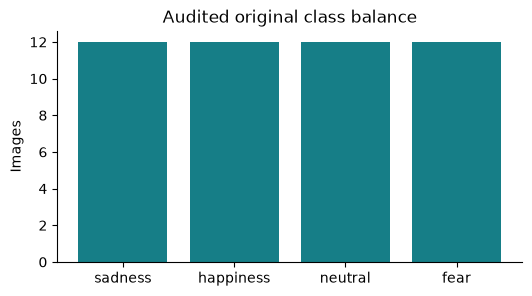

In [3]:
from prml.data import audit
audit_result = audit(rows)
display(pd.DataFrame([{'original_dimensions': k, 'images': v} for k, v in audit_result['dimensions'].items()]))
print('Near-duplicate candidates:', len(audit_result['near_duplicates']))
print('Cross-subject candidates:', sum(not p['same_subject'] for p in audit_result['near_duplicates']))
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(CLASSES, [audit_result['counts'][c] for c in CLASSES], color='#167E87')
ax.set(title='Audited original class balance', ylabel='Images'); display(fig); plt.close(fig)

## 5. Seed-42 shuffle and subject-independent partitions
The shuffled subject order and complete records are saved in `split_manifest.json`. All four classes occur in every partition. Both models use exactly the same membership. Training uses random horizontal flips; final train/validation/test metrics all use unaugmented images.

In [4]:
print('Shuffled subject order:', split_manifest['shuffled_subject_order'])
display(pd.DataFrame([{'partition': name, 'subjects': ', '.join(p['subjects']), 'images': p['images'], 'actual_ratio': p['actual_ratio'], **p['class_counts']}
                      for name, p in split_manifest['partitions'].items()]))
subject_sets = [{r['subject'] for r in parts[name]} for name in SPLIT_NAMES]
assert not (subject_sets[0] & subject_sets[1] or subject_sets[0] & subject_sets[2] or subject_sets[1] & subject_sets[2])
assert [len(parts[n]) for n in SPLIT_NAMES] == [24, 16, 8]
print('No subject overlap. Total records:', sum(map(len, parts.values())))

Shuffled subject order: ['116', '079', '168', '140', '066', '004']


,partition,subjects,images,actual_ratio,happiness,neutral,sadness,fear
0,train,"116, 079, 168",24,0.500000,6,6,6,6
1,validation,"140, 066",16,0.333333,4,4,4,4
2,test,004,8,0.166667,2,2,2,2


No subject overlap. Total records: 48


## 6. Preprocessing and CNN
EXIF orientation → RGB → bilinear 64×64 resize → pixels in [−1,1]. The checkpoint-compatible CNN has conv/BN/ReLU/max-pool blocks at 16,32,64 channels; a 4096→64→4 dense head; dropout 0.3. The last layer emits logits; softmax is used for inference.

$$Y_{i,j,k}=\sum_{m,n,c} W_{m,n,c,k}X_{i+m,j+n,c}+b_k$$

$$p(y=k|x)=\frac{e^{z_k}}{\sum_{j=1}^{4}e^{z_j}},\qquad L_{CNN}=-\log p(y|x).$$

In [5]:
cnn = CNN()
discriminator = Discriminator()
generator = Generator()
display(pd.DataFrame([{'network': name, 'parameters': sum(p.numel() for p in net.parameters())}
                      for name, net in [('CNN', cnn), ('Discriminator', discriminator), ('Generator', generator)]]))
x = torch.zeros(2, 3, SIZE, SIZE)
assert cnn(x).shape == (2, 4)
fake = generator(torch.randn(2, LATENT), torch.tensor([0, 3]))
source_logits, class_logits = discriminator(fake)
assert fake.shape == (2, 3, 64, 64)
assert source_logits.shape == (2,) and class_logits.shape == (2, 4)
print('CNN, generator and discriminator tensor dimensions verified.')
del cnn, discriminator, generator, fake

,network,parameters
0,CNN,286276
1,Discriminator,710629
2,Generator,1022179


CNN, generator and discriminator tensor dimensions verified.


## 7. AC-GAN objective and correct gradient flow
The class-conditioned generator takes Gaussian noise and a label embedding. The discriminator emits source and expression logits; **its expression head performs classification**.

$$L_D=BCE(D_s(x),1)+BCE(D_s(G(z,c)),0)+CE(D_c(x),c)+CE(D_c(G(z,c)),c)$$

$$L_G=BCE(D_s(G(z,c)),1)+CE(D_c(G(z,c)),c).$$

All terms have unit weights. The generator source term is the explicitly non-saturating variant. Fake tensors detach for discriminator updates; discriminator weights freeze while retaining input gradients for generator updates. The generator checkpoint is saved at the same validation-selected epoch as the discriminator.

## 8. Fixed training and validation protocol
CNN: **25 epochs**. AC-GAN: **40 epochs**. Batch **8**, Adam lr **0.0002**. CNN betas=(0.9,0.999); GAN betas=(0.5,0.999). Seed **42** resets before each method. The best checkpoint minimizes validation classification cross-entropy. Test images do not enter training, augmentation, preprocessing fitting or model selection. No search is performed against test performance.

The next cell trains when no completed run exists. A matching completed run is replay-verified and reused, rather than silently retrained. To intentionally repeat training, use a new `RUN_DIR`; keep the split and budgets fixed.

In [6]:
reusing = (RUN_DIR / 'summary.json').exists()
summary = run_experiment(DATA_ZIP, DATA_DIR, RUN_DIR, ROOT / 'results/duplicate_review.json',
                         seed=42, cnn_epochs=25, gan_epochs=40, device='cpu')
print('Replayed and reused matching completed experiment.' if reusing else 'Executed new experiment and replay-verified saved checkpoints.')
display(pd.DataFrame([{'model': k, 'selected_epoch': v['best_epoch'], 'training_seconds': v['training_seconds']} for k, v in summary['models'].items()]))

Replayed and reused matching completed experiment.


,model,selected_epoch,training_seconds
0,cnn,25,1.729341
1,gan,8,7.112640


## 9. Separate final training report
Training metrics below are measured on unaugmented training images using the frozen selected checkpoint. They describe fit to seen subjects, not out-of-sample generalization.

In [7]:
metric_keys = ['loss', 'accuracy', 'balanced_accuracy', 'macro_precision', 'macro_recall', 'macro_f1']
def partition_table(name):
    return pd.DataFrame({k.upper(): {m: v['partitions'][name][m] for m in metric_keys} for k, v in summary['models'].items()})
display(partition_table('train'))

,CNN,GAN
loss,0.42156,1.347494
accuracy,1.00000,0.250000
balanced_accuracy,1.00000,0.250000
macro_precision,1.00000,0.062500
macro_recall,1.00000,0.250000
macro_f1,1.00000,0.100000


## 10. Separate final validation report
These subjects select the checkpoint. Validation performance is selection-biased and must not be labeled test accuracy.

In [8]:
display(partition_table('validation'))

,CNN,GAN
loss,1.115357,1.353999
accuracy,0.812500,0.250000
balanced_accuracy,0.812500,0.250000
macro_precision,0.854167,0.125000
macro_recall,0.812500,0.250000
macro_f1,0.804167,0.166667


## 11. Separate frozen-model test report
This is one held-out subject and eight images. A single changed prediction moves accuracy by **12.5 percentage points**. The test set stays fixed and is not used to choose a seed, epoch budget, learning rate or public classifier.

In [9]:
display(partition_table('test'))
display(pd.DataFrame([{'model': kind.upper(), 'class': cls, **{m: model['partitions']['test'][m + '_by_class'][cls] for m in ['precision', 'recall', 'f1']}}
                      for kind, model in summary['models'].items() for cls in CLASSES]))

,CNN,GAN
loss,1.179621,1.375723
accuracy,0.375000,0.250000
balanced_accuracy,0.375000,0.250000
macro_precision,0.183333,0.062500
macro_recall,0.375000,0.250000
macro_f1,0.242857,0.100000


,model,class,precision,recall,f1
0,CNN,sadness,0.000000,0.0,0.000000
1,CNN,happiness,0.400000,1.0,0.571429
2,CNN,neutral,0.000000,0.0,0.000000
3,CNN,fear,0.333333,0.5,0.400000
4,GAN,sadness,0.000000,0.0,0.000000
5,GAN,happiness,0.000000,0.0,0.000000
6,GAN,neutral,0.250000,1.0,0.400000
7,GAN,fear,0.000000,0.0,0.000000


## 12. Learning curves and confusion matrices
Validation CE selects the checkpoint. Loss magnitudes differ across objectives, so compare classification metrics rather than raw CNN/GAN losses.

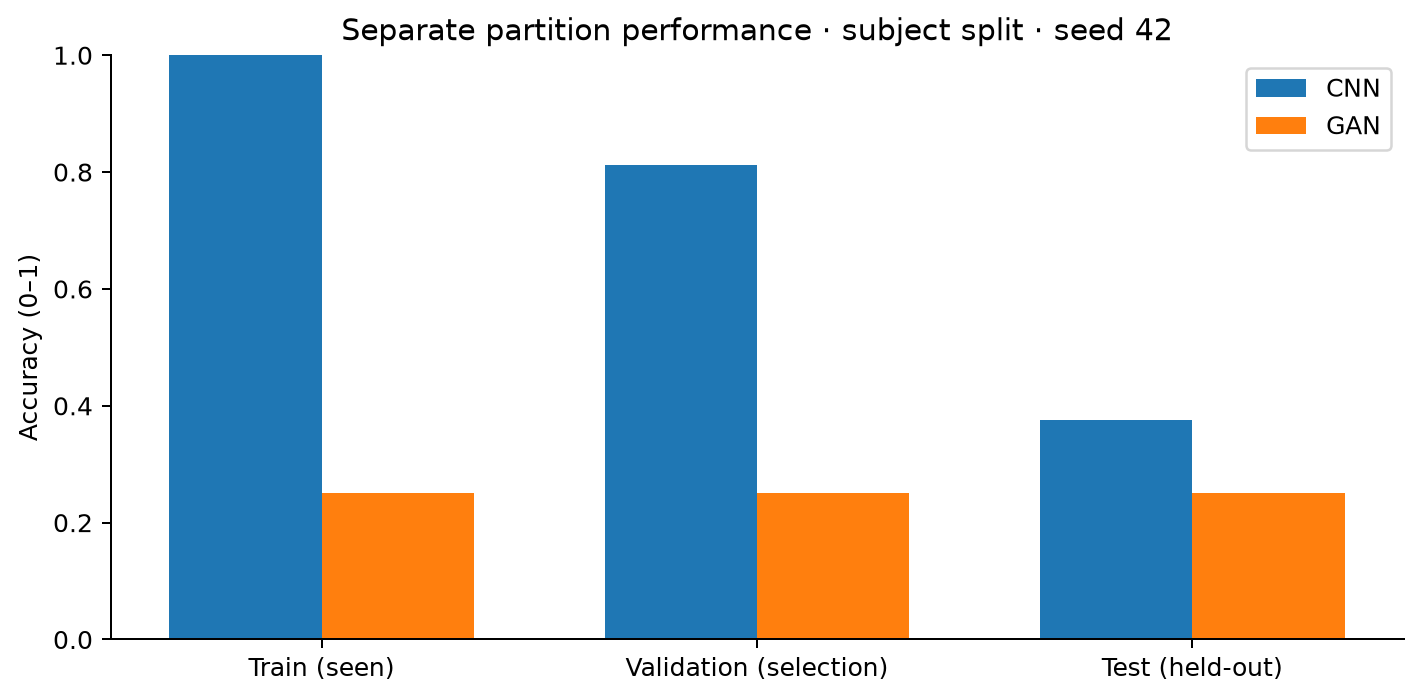

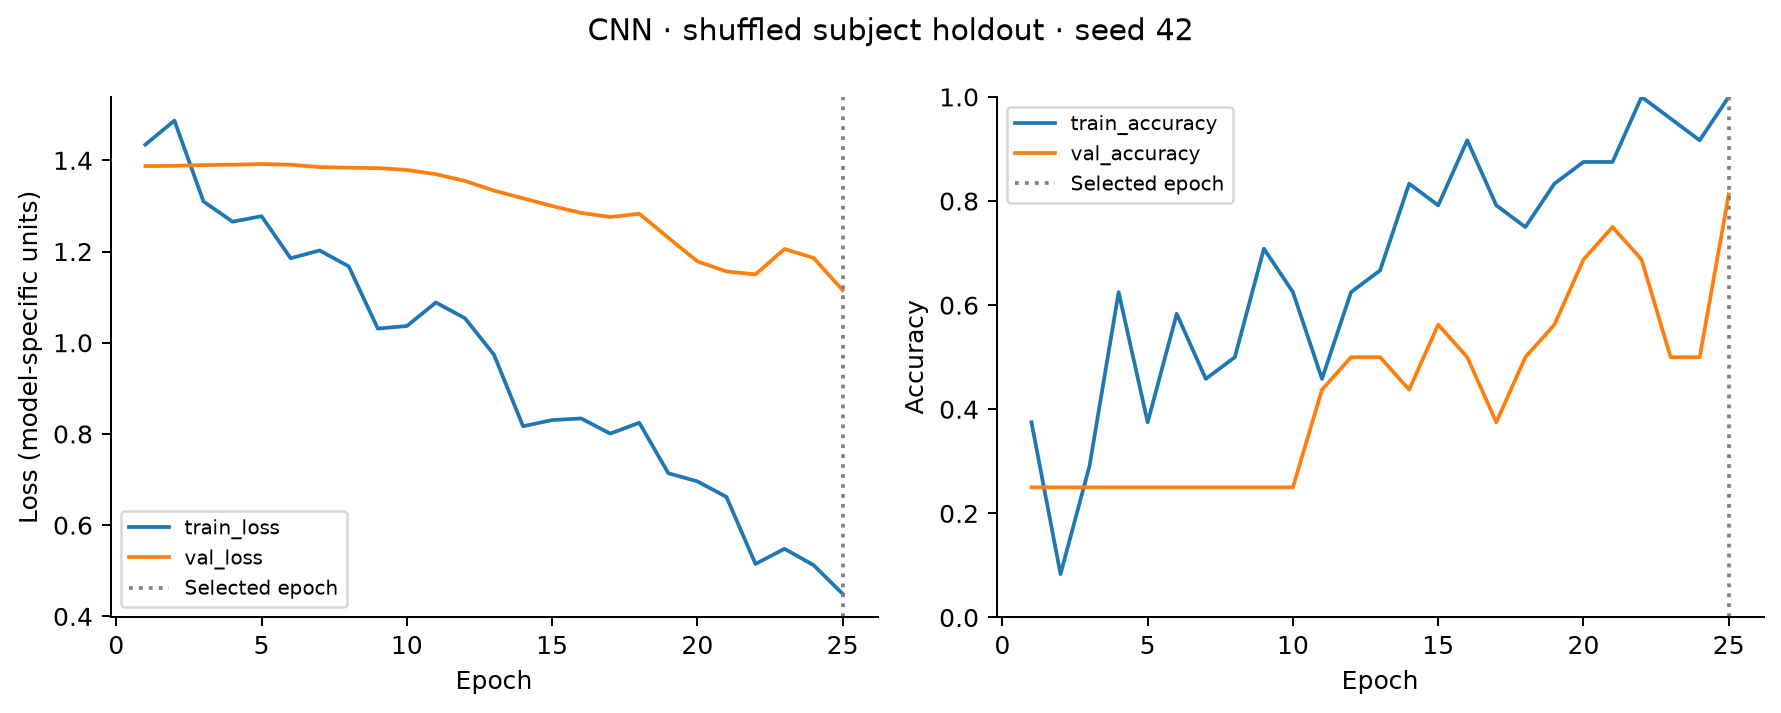

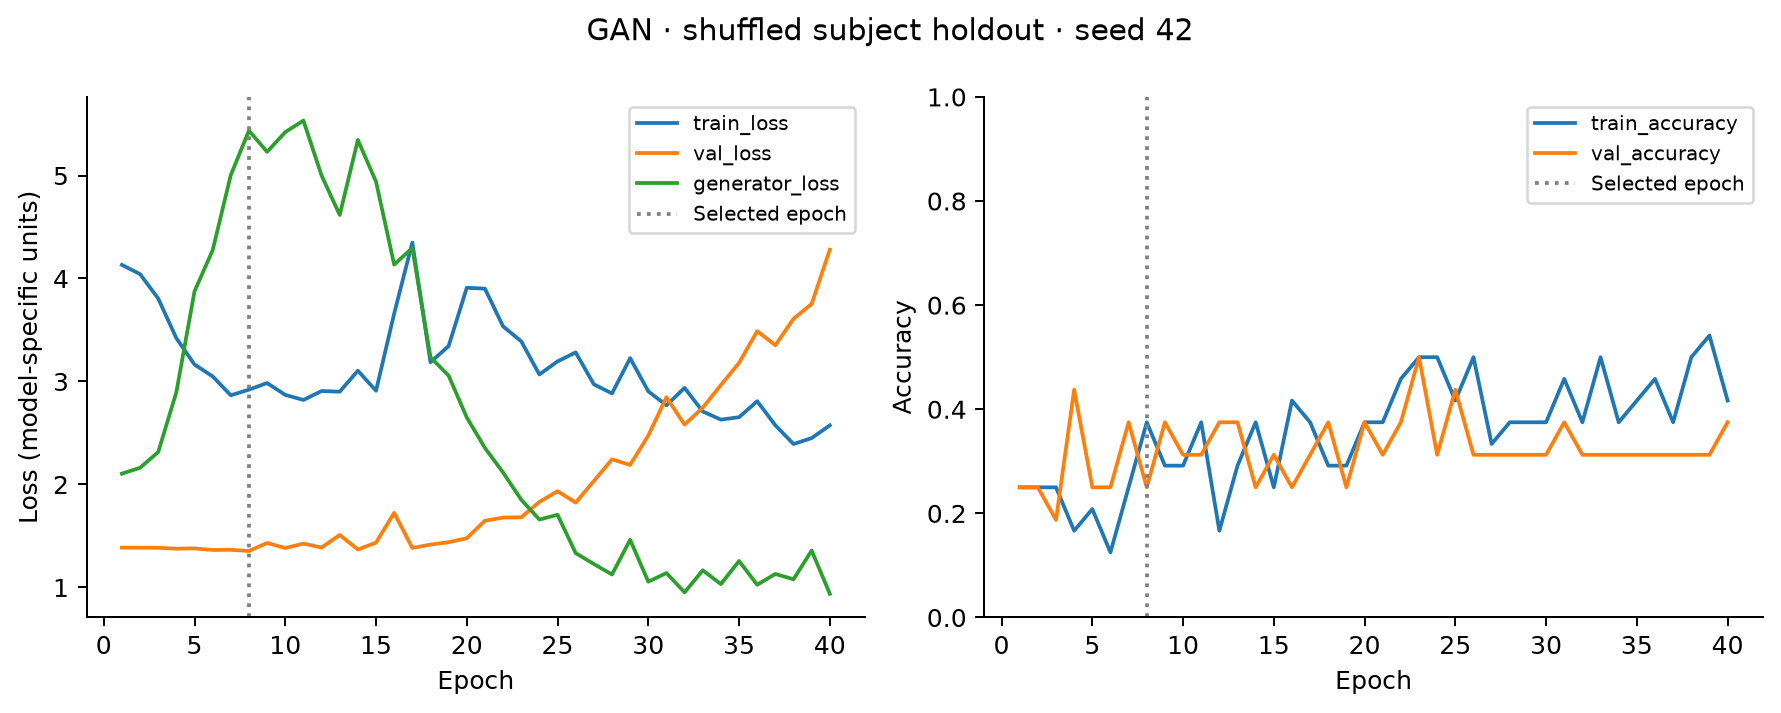

In [10]:
export_experiment(RUN_DIR, PUBLIC_RESULTS, ROOT / 'deployment')
build_reports(PUBLIC_RESULTS, ROOT / 'reports/seed42')
display(DisplayImage(filename=str(PUBLIC_RESULTS / 'figures/split_accuracy.png')))
for kind in ['cnn', 'gan']:
    display(DisplayImage(filename=str(PUBLIC_RESULTS / f'figures/{kind}_history.png')))

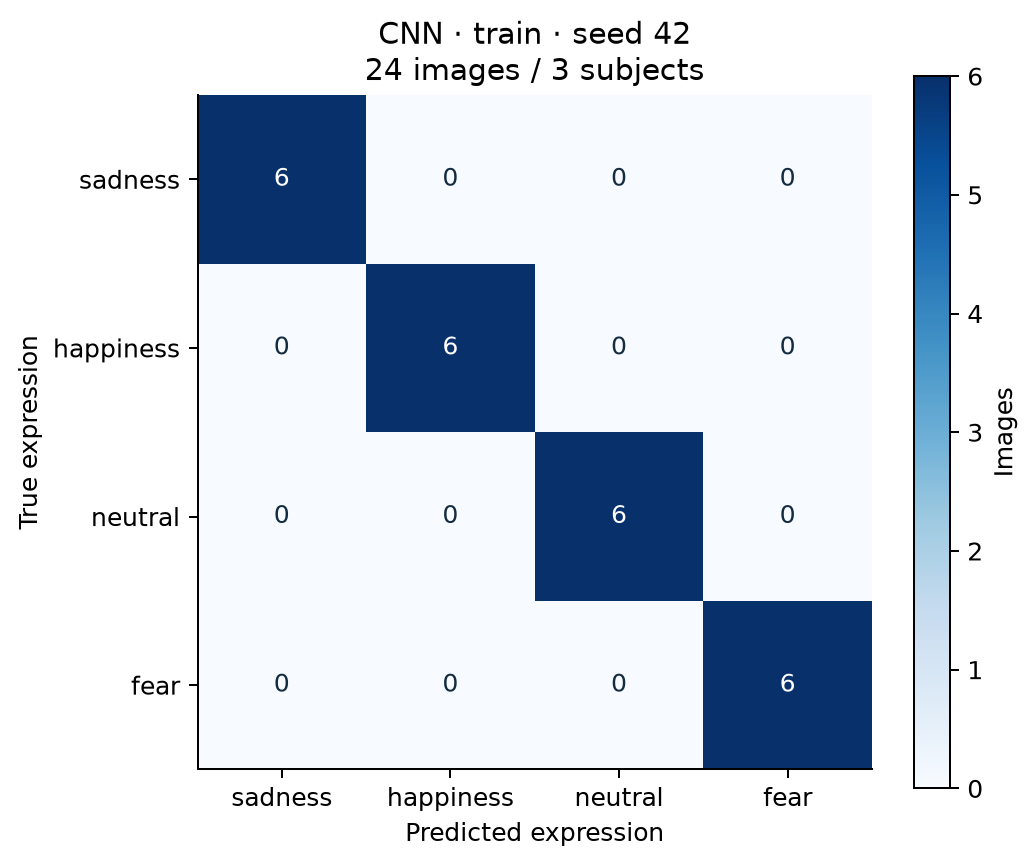

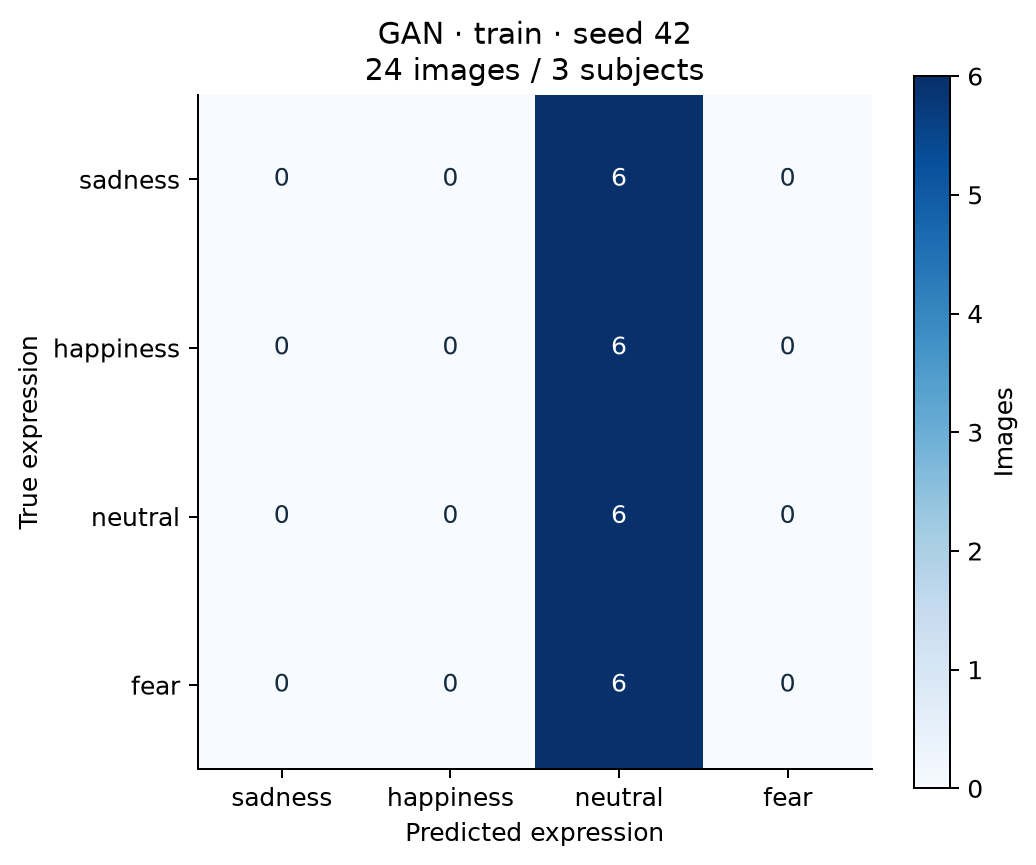

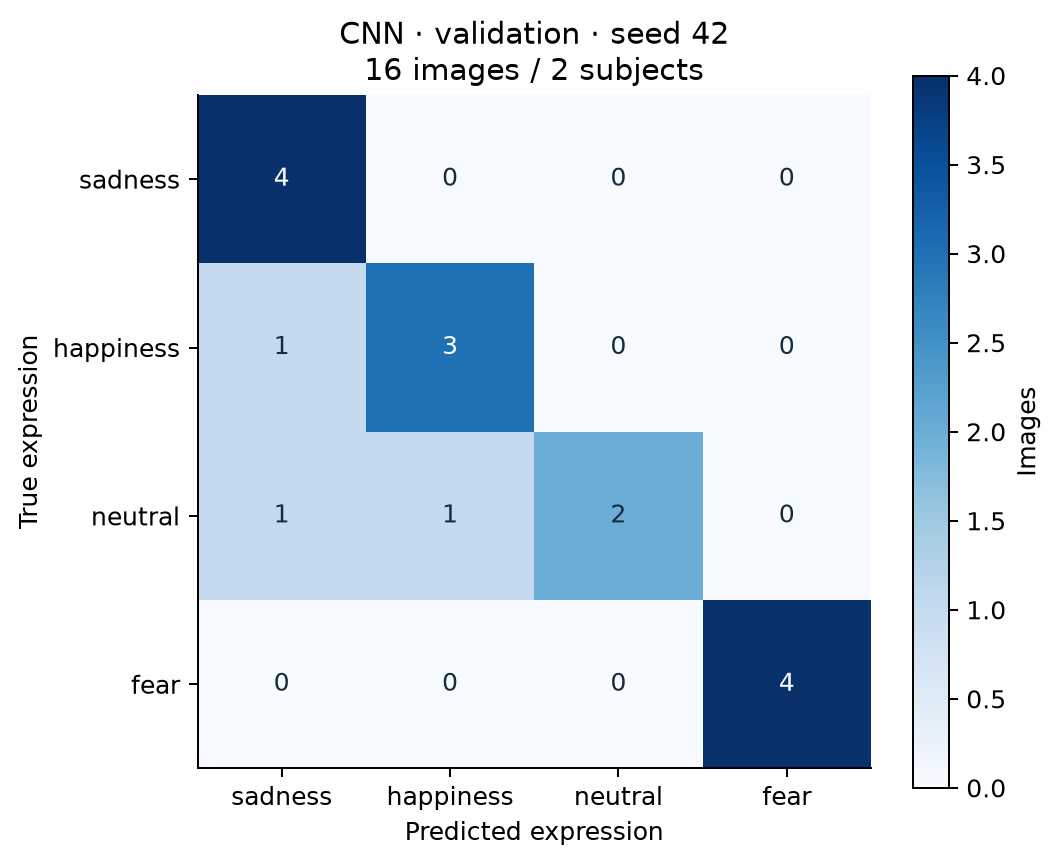

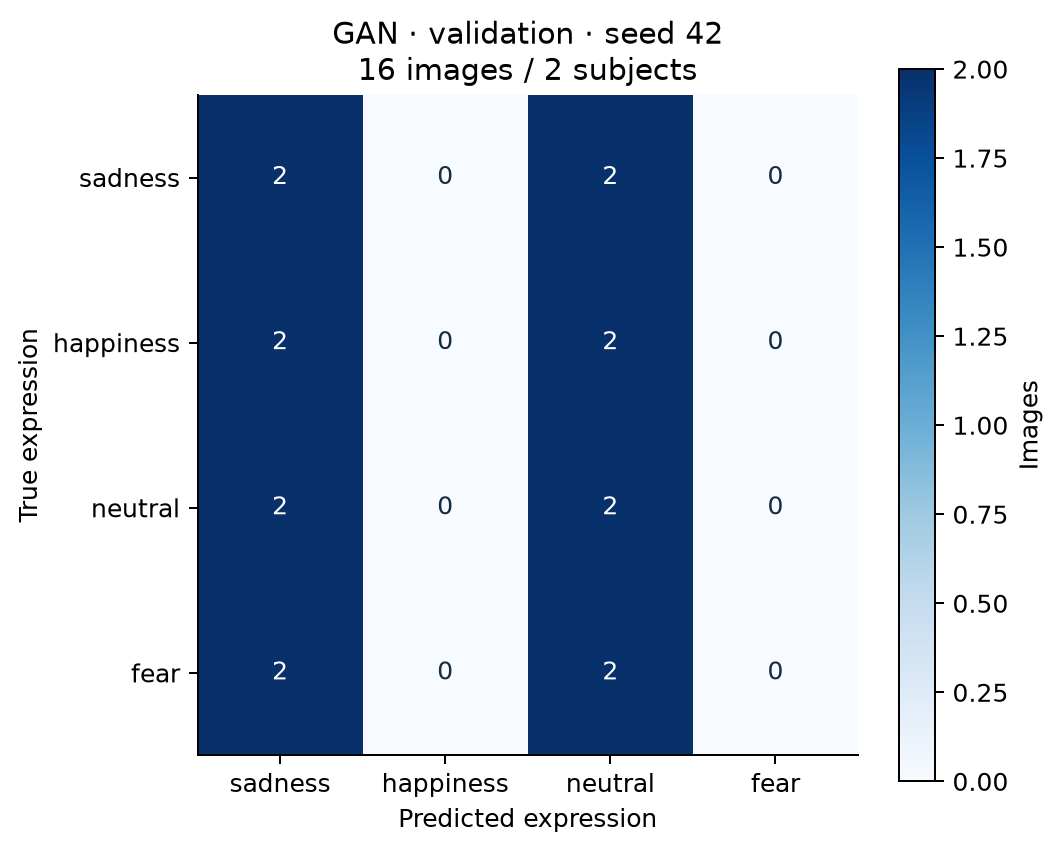

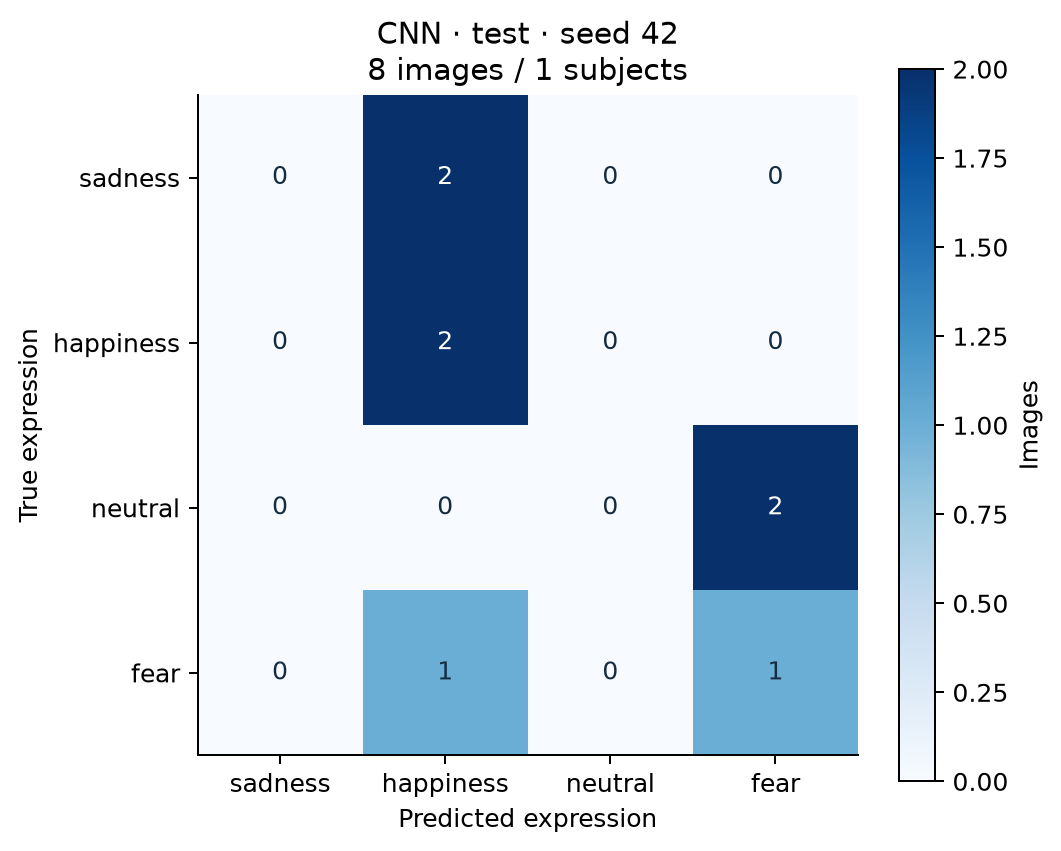

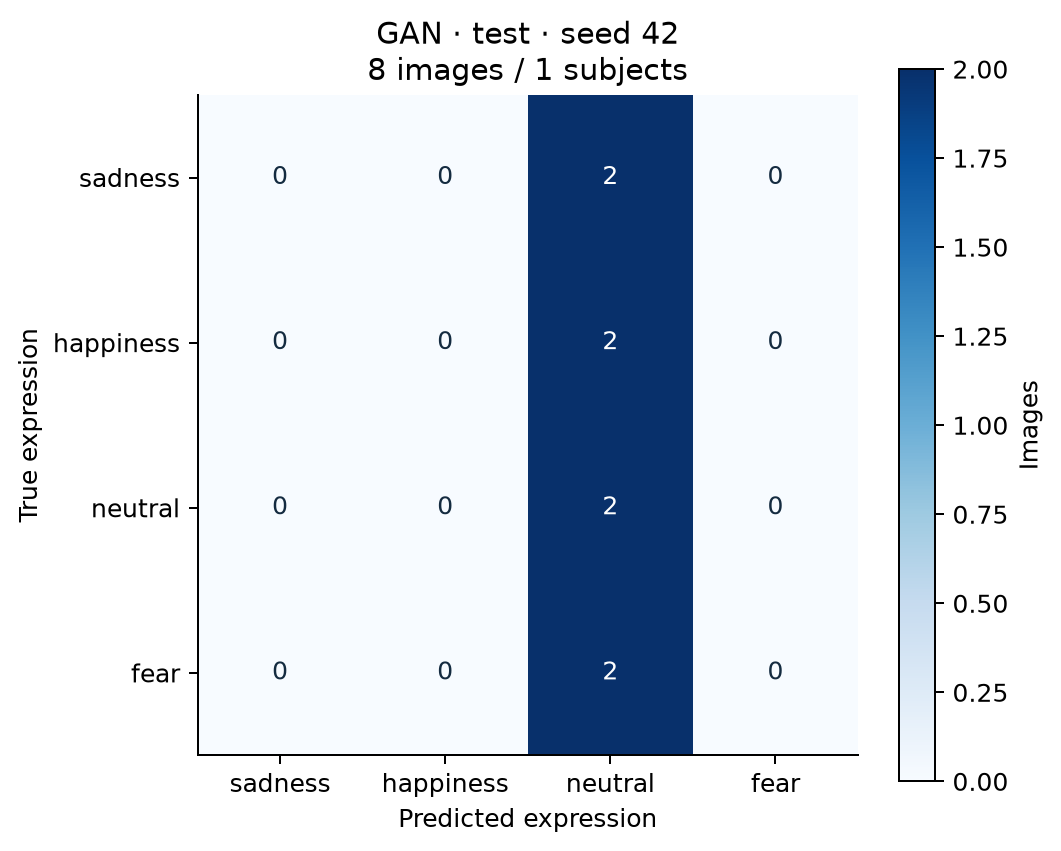

In [11]:
for split in SPLIT_NAMES:
    for kind in ['cnn', 'gan']:
        display(DisplayImage(filename=str(PUBLIC_RESULTS / f'figures/{split}_{kind}_confusion.png')))

## 13. Per-image prediction evidence and checkpoint replay
The following table contains codes and probabilities, not source photographs. Both saved classifiers are replayed on all three partitions. Replaying verifies saved outputs; it does not change the checkpoint or tune the model.

In [12]:
prediction_rows = []
for kind, model in summary['models'].items():
    for split, measured in model['partitions'].items():
        for p in measured['predictions']:
            prediction_rows.append({'model': kind, 'partition': split, **p})
prediction_frame = pd.DataFrame(prediction_rows)
display(prediction_frame[prediction_frame['partition'] == 'test'])
verify_checkpoints(parts, RUN_DIR, summary)
display(pd.DataFrame(json.loads((RUN_DIR / 'verification.json').read_text())['checks']))

,model,partition,filename,subject,true,predicted,probabilities
40,cnn,test,004_o_m_s_a.jpg,004,sadness,happiness,"[0.3244856297969818, 0.40406957268714905, 0.03..."
41,cnn,test,004_o_m_s_b.jpg,004,sadness,happiness,"[0.27187982201576233, 0.433590292930603, 0.021..."
42,cnn,test,004_o_m_h_a.jpg,004,happiness,happiness,"[0.22532859444618225, 0.5513266324996948, 0.01..."
43,cnn,test,004_o_m_n_b.jpg,004,neutral,fear,"[0.23629549145698547, 0.20926281809806824, 0.0..."
44,cnn,test,004_o_m_f_a.jpg,004,fear,fear,"[0.18145781755447388, 0.20743951201438904, 0.0..."
45,cnn,test,004_o_m_n_a.jpg,004,neutral,fear,"[0.20556865632534027, 0.1263001263141632, 0.17..."
46,cnn,test,004_o_m_f_b.jpg,004,fear,happiness,"[0.22026866674423218, 0.3899080455303192, 0.01..."
47,cnn,test,004_o_m_h_b.jpg,004,happiness,happiness,"[0.2183864414691925, 0.4449634253978729, 0.053..."
88,gan,test,004_o_m_s_a.jpg,004,sadness,neutral,"[0.1704944372177124, 0.26845213770866394, 0.36..."
89,gan,test,004_o_m_s_b.jpg,004,sadness,neutral,"[0.16159816086292267, 0.2655700147151947, 0.37..."


,model,partition,images,replay_verified
0,cnn,train,24,True
1,cnn,validation,16,True
2,cnn,test,8,True
3,gan,train,24,True
4,gan,validation,16,True
5,gan,test,8,True


## 14. Inference example without publishing a face
Use a locally supplied authorized image for a real demonstration. This notebook uses an in-memory gray test image to verify the inference API only; the result is not a face-recognition claim. No image is sent to a server from this cell. Softmax scores are uncalibrated.

In [13]:
import io
from PIL import Image
buffer = io.BytesIO()
Image.new('RGB', (64, 64), (128, 128, 128)).save(buffer, format='PNG')
for kind in ['cnn', 'gan']:
    model, metadata = load_checkpoint(RUN_DIR / f'{kind}.pt')
    buffer.seek(0)
    scores = predict(model, kind, buffer)
    assert abs(sum(scores.values()) - 1) < 1e-6
    print(kind, scores)

cnn {'sadness': 0.26360633969306946, 'happiness': 0.18884988129138947, 'neutral': 0.29850900173187256, 'fear': 0.2490347921848297}
gan {'sadness': 0.2376023679971695, 'happiness': 0.25539249181747437, 'neutral': 0.2624925673007965, 'fear': 0.24451255798339844}


## 15. Interpretation and limitations
Read the executed results above: high training fit does not establish generalization. Compare validation and test separately, and preserve negative results. Chance-level expected accuracy is 25% for four balanced classes, but a constant predictor also obtains 25%. One test identity cannot support a reliable population confidence interval. Repeated seeds, external subjects, larger licensed datasets, calibration and architecture-matched ablations are future work. No synthetic realism/diversity claim is made. Classification describes apparent expression labels, not actual emotions or mental state.

## 16. Deliverables, privacy and deployment
Separate Markdown reports are under `reports/seed42/`; metrics, split manifests, histories and statistical figures are under `results/holdout_seed42/`. The two validation-selected classifier checkpoints are packaged for the requested public inference. Original photographs, ZIP and generator weights remain ignored/private. The public application never retrains on startup and handles uploads in memory.

```bash
python -m pytest -q
python -m streamlit run app/streamlit_app.py
```

## 17. References
1. LeCun et al. (1998), [Gradient-Based Learning Applied to Document Recognition](https://bottou.org/papers/lecun-98h).
2. Goodfellow et al. (2014), [Generative Adversarial Networks](https://arxiv.org/abs/1406.2661).
3. Odena, Olah and Shlens (2017), [Conditional Image Synthesis With Auxiliary Classifier GANs](https://arxiv.org/abs/1610.09585).
4. [Project repository](https://github.com/Ahmdullah16/PRML-Assignment).